# Preliminaries

Evaluation of **Concept Activation Vectors** on the test set using the library `Xplique`.

In [1]:
!pwd
import sys
sys.path.append('./xplique/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import os, cv2, glob, time, pickle
import numpy as np
from matplotlib import pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import ttest_ind
print(tf.__version__)
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers

from xplique.concepts import Cav, Tcav

2.8.1
No module named 'nltk'


2024-02-08 14:08:38.802446: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-08 14:08:39.248659: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
metafolder = './beexplainable/metafiles/Fungi/raw/'

FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'
CONCEPTS_PATH = '../data/DanishFungi/Concepts_3spec/'
IMAGES_PATH = metafolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + 'classes.txt'

MODELS_PATH  = './beexplainable/models/'

In [4]:
new_random = False # whether to find new random images (otherwise reload the older ones)

# Load images

In [5]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

batch_size = len(file_ids)
img_height = img_width = 224

In [6]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

In [7]:
# Conversion to tf.Dataset
train_val_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
train_val_set = train_val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
train_val_set = train_val_set.map(lambda x, y: (normalization_layer(x), y))

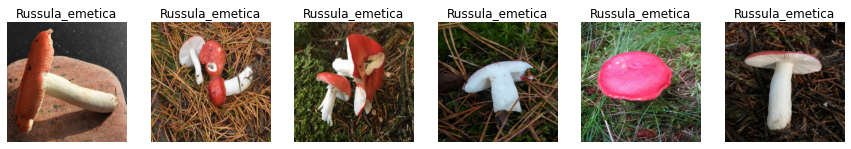

In [8]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_val_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

# Load random images from **broden**

In [9]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

if new_random:

    nb_samples = 1000
    files = [img for img in random_imgs]
    files = list(filter(random_imgs_filter, files))
    files = np.random.choice(files, nb_samples, replace=False)
    with open(metafolder + 'fungi_tcav_random.pickle', 'wb') as handle:
        pickle.dump(files, handle, protocol=pickle.HIGHEST_PROTOCOL)

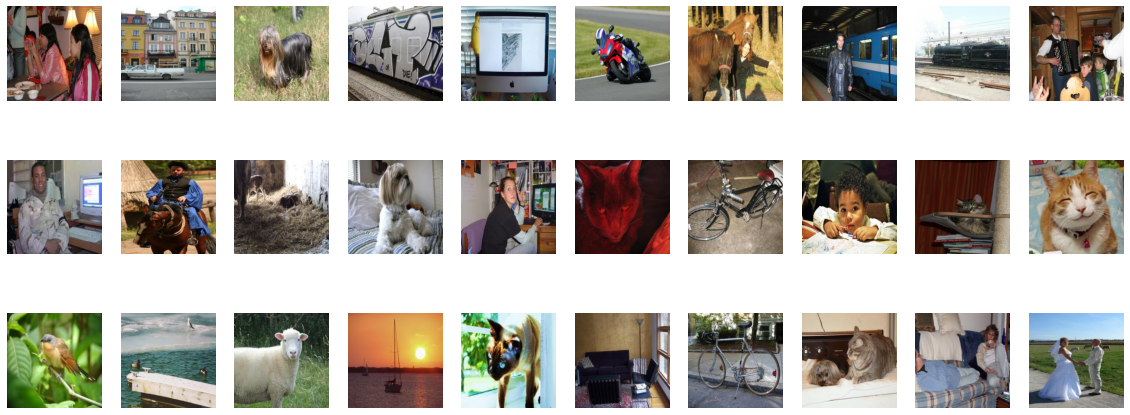

In [10]:
with open(metafolder + 'fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([img/255.0 for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

# Load concepts generated with Stable Diffusion

In [11]:
concept_folder = CONCEPTS_PATH

concepts_files = os.listdir(concept_folder)
concepts_availables = np.unique([t for t in concepts_files])
print('The available concepts are : \n', '; '.join(concepts_availables))

def load_concept(concept):
    files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg')
    imgs  = [cv2.imread(img)[...,::-1] for img in files]
    imgs  = [tf.image.resize(img, [img_width, img_height]) for img in imgs]
    imgs = [img/255.0 for img in imgs]

    return np.array(imgs)

The available concepts are : 
 bright_red; reddish_orange; rose_red




Texture: bright_red  - shape: (30, 224, 224, 3)


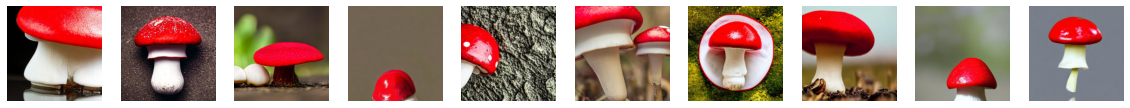



Texture: reddish_orange  - shape: (30, 224, 224, 3)


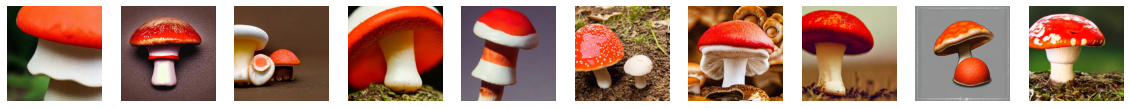



Texture: rose_red  - shape: (30, 224, 224, 3)


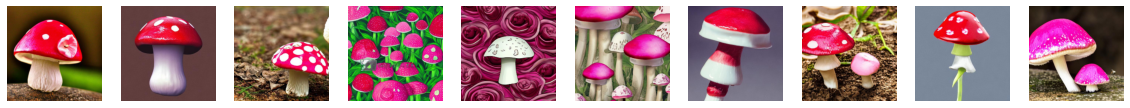

In [12]:
concepts = {concept: load_concept(concept) for concept in concepts_availables}

plt.rcParams["figure.figsize"] = [20, 8]
for concept_name, images in concepts.items():
    print(f"\n\nTexture: {concept_name}  - shape: {images.shape}")
    for i in range(10):
        plt.subplot(1, 10, i+1)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

# Load model

In [13]:
# Define initial training and other model parameters
drop_rate = 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
#dataset_type = 'mini' if use_mini_dataset else 'all'
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi'
print(model_name)
weights_file = MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5' # path from which to load weights

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_raw_Fungi


In [14]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

# Extract the Concept Activation Vectors (CAV)

To extract this concept vector, we need positive elements (containing the concept) and negative elements (not containing the concept).

In [15]:
# Define layer whose outputs will represent the latent space for the CAV
layer_target = 'CNN_Blocks_ResNet50_iNat_raw_Fungi'

# Remove the softmax because we are only interested in the value of the logits
model.layers[-1].activation = tf.keras.activations.linear

In [16]:
cavs = {}
cav_extractor = Cav(model, layer_target, batch_size=64)

for concept_name, imgs in concepts.items():

    cav = cav_extractor(imgs, random_dataset)

    cavs[concept_name] = cav

    print(f'Concept Activation Vector for {concept_name} computed.')

2024-02-08 14:09:15.109237: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-02-08 14:09:15.623858: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-08 14:09:15.624999: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-08 14:09:15.625010: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-02-08 14:09:15.626142: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-08 14:09:15.626191: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


Concept Activation Vector for bright_red computed.
Concept Activation Vector for reddish_orange computed.
Concept Activation Vector for rose_red computed.


# Test the CAVs

Here we will test the extracted concepts on some classes.

We start by extracting several CAVs by varying the random elements, then we will test the average effectiveness of these CAVs against random CAVs.

In [17]:
cavs = {}
nb_repeat = 30

for concept_name, imgs in concepts.items():

    for repeat_id in range(nb_repeat):
        # Choose different random images for each cav repetition
        random_ids = np.random.choice(len(random_dataset), len(imgs))
        cav = cav_extractor(imgs, random_dataset[random_ids])

        if concept_name not in cavs:
            cavs[concept_name] = []

        cavs[concept_name].append(cav)

    print(f"Done for concept {concept_name}.")

Done for concept bright_red.
Done for concept reddish_orange.
Done for concept rose_red.


In [18]:
# Do the same things for random images
for repeat_id in range(nb_repeat):
    # Choose many random images, half as positive and half as negative
    random_ids = np.random.choice(len(random_dataset), 500)
    random_1, random_2 = random_ids[:250], random_ids[250:]

    cav = cav_extractor(random_dataset[random_1], random_dataset[random_2])

    if 'random' not in cavs:
        cavs['random'] = []

    cavs['random'].append(cav)

print(f"Done for Random.")

Done for Random.


### Measure Cos-Sim and BCE of predicted concepts

In [19]:
# One-hot-encode the concepts
enc = OneHotEncoder().fit([[0], [1], [2]])
concept_basis = enc.transform([[0], [1], [2]]).toarray()
# bright_red = 100 -> emetica
# orange_red = 010 -> paludosa
# rose_red   = 001 -> rosea
lookup_cls_concepts = [concept_basis[0],
                       concept_basis[1],
                       concept_basis[2]]
lookup_cls_concepts[2]

array([0., 0., 1.])

In [20]:
count = 0
probs_cls_dict = {}
start_time = time.time()
for explained_spec in range(len(classes)):

    ### Compute TCAV scores ###
    imgs_cav = train_val_set.unbatch()
    imgs_cav = imgs_cav.filter(lambda img_cav, lab: lab == explained_spec)
    imgs_cav = imgs_cav.map(lambda img_cav, lab: tf.numpy_function(np.array, [img_cav], tf.float32))
    imgs_cav = list(imgs_cav.as_numpy_iterator())
    imgs_cav = np.array(imgs_cav)

    tcav_scores = {}
    cls_name = classes[explained_spec]
    tcav_scores[cls_name] = {}
    cav_tester = Tcav(model, layer_target)

    # For the chosen concept, we take all the CAVs and test them against that class
    for concept_name, _cavs in cavs.items():
        tcav_scores[cls_name][concept_name] = []
        for cav in _cavs:
            score = cav_tester(imgs_cav, explained_spec, cav)
            tcav_scores[cls_name][concept_name].append(score)

    concept_score = []
    for concept_id, concept_name in enumerate(tcav_scores[cls_name].keys()):
        scores = tcav_scores[cls_name][concept_name]
        mean = np.mean(scores)
        std = np.std(scores)
        concept_score.append((concept_name, mean, std))

    means = [mean for concept_name, mean, std in concept_score]
    # The p-values will attest to the significance of a cav in relation to random cavs
    #p_values = [ttest_ind(tcav_scores[cls_name][concept_name],
    #                     tcav_scores[cls_name]['random'], equal_var = True)[1]
    #           for concept_name in tcav_scores[cls_name].keys()]
    probs_cls_dict[classes[explained_spec]] = np.asarray(means[:-1])
    print(classes[explained_spec] + ' done.')
print("--- %s seconds ---" % (time.time() - start_time))

Russula_emetica done.
Russula_paludosa done.
Russula_rosea done.
--- 108.5708658695221 seconds ---


In [21]:
probs_cls_soft = tf.keras.activations.softmax(tf.convert_to_tensor(list(probs_cls_dict.values())))
probs_cls_soft

<tf.Tensor: shape=(3, 3), dtype=float64, numpy=
array([[0.34407347, 0.34165893, 0.31426761],
       [0.35865352, 0.30049026, 0.34085622],
       [0.29127385, 0.35571506, 0.3530111 ]])>

In [22]:
for explained_spec in range(len(classes)):

    probs = probs_cls_soft[explained_spec].numpy()
    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[explained_spec]
    # Compute cosine sim.
    cos_sim = cosine_similarity(true_con.reshape(1, -1), probs.reshape(1, -1))[0][0]
    # Compute binary cross entropy
    bce = log_loss(true_con, probs)

    print(classes[explained_spec])
    print('Cosine Similarity:')
    print(cos_sim)
    print('BCE:')
    print(bce);print()

Russula_emetica
Cosine Similarity:
0.595463306844723
BCE:
0.6207333448793563

Russula_paludosa
Cosine Similarity:
0.519083108044346
BCE:
0.6877796544168935

Russula_rosea
Cosine Similarity:
0.609010616604282
BCE:
0.6083853517233173



In [23]:
probs_con_dict = {}
con_list = list(concepts.keys())
for c in con_list:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_soft[i][con_list.index(c)]
probs_con_dict

{'bright_red': array([0.34407347, 0.35865352, 0.29127385]),
 'reddish_orange': array([0.34165893, 0.30049026, 0.35571506]),
 'rose_red': array([0.31426761, 0.34085622, 0.3530111 ])}

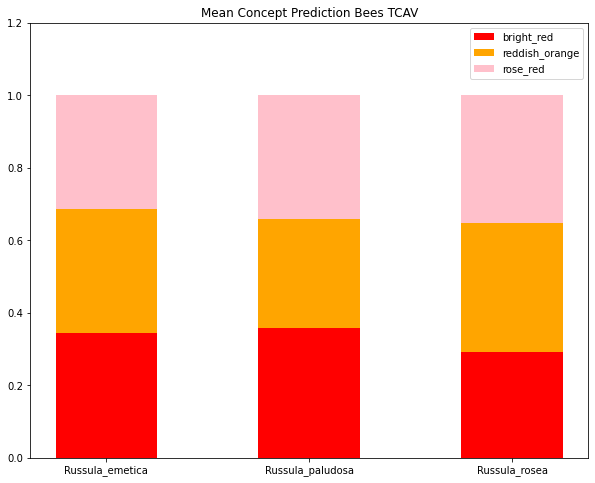

In [24]:
con_colors = ['red', 'orange', 'pink']
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.2)
plt.legend(loc='upper right')
plt.title('Mean Concept Prediction Bees TCAV')
plt.show()

### Frequency of significant concepts

In [20]:
pvals_cls_dict = {}
for c in classes:
    pvals_cls_dict[c] = np.zeros(3, dtype=np.uint8)
pvals_cls_dict

{'Russula_emetica': array([0, 0, 0], dtype=uint8),
 'Russula_paludosa': array([0, 0, 0], dtype=uint8),
 'Russula_rosea': array([0, 0, 0], dtype=uint8)}

In [21]:
count = 0
start_time = time.time()
for img_cav, explained_spec in train_val_set.unbatch():

    ### Compute TCAV scores ###
    img_cav = tf.expand_dims(img_cav, axis=0)
    imgs_cav = tf.numpy_function(np.array, [img_cav], tf.float32)

    tcav_scores = {}
    cls_name = classes[explained_spec]
    tcav_scores[cls_name] = {}
    cav_tester = Tcav(model, layer_target)

    # For the chosen concept, we take all the CAVs and test them against that class
    for concept_name, _cavs in cavs.items():
        tcav_scores[cls_name][concept_name] = []
        for cav in _cavs:
            score = cav_tester(imgs_cav, explained_spec, cav)
            tcav_scores[cls_name][concept_name].append(score)

    concept_score = []
    for concept_id, concept_name in enumerate(tcav_scores[cls_name].keys()):
        scores = tcav_scores[cls_name][concept_name]
        mean = np.mean(scores)
        std = np.std(scores)
        concept_score.append((concept_name, mean, std))

    # The p-values will attest to the significance of a cav in relation to random cavs
    p_values = np.array([ttest_ind(tcav_scores[cls_name][concept_name],
                         tcav_scores[cls_name]['random'], equal_var = True)[1]
               for concept_name in tcav_scores[cls_name].keys()])

    pvals_cls_dict[classes[explained_spec]] += np.array(p_values[:-1] < 0.05, dtype=np.uint8)
    if count % 50 == 0: print(count)
    count += 1

print("--- %s seconds ---" % (time.time() - start_time))
pvals_cls_dict

/tmp/ipykernel_1536571/3599180741.py:29: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  p_values = np.array([ttest_ind(tcav_scores[cls_name][concept_name],


0
50
100
150
200
250
300
350
400
450
500
550
600
650
--- 2050.1587374210358 seconds ---


{'Russula_emetica': array([142, 142, 142], dtype=uint8),
 'Russula_paludosa': array([162,  23, 252], dtype=uint8),
 'Russula_rosea': array([179, 175,  83], dtype=uint8)}

In [22]:
with open(metafolder + 'pvals_cls_dict.pkl', 'wb') as f:
    pickle.dump(pvals_cls_dict, f)
with open(metafolder + 'pvals_cls_dict.pkl', 'rb') as f:
    pvals_cls_dict = pickle.load(f)
pvals_cls_dict

{'Russula_emetica': array([142, 142, 142], dtype=uint8),
 'Russula_paludosa': array([162,  23, 252], dtype=uint8),
 'Russula_rosea': array([179, 175,  83], dtype=uint8)}

In [30]:
# Normalize frequencies
for i in range(len(classes)):
    len_cls = np.count_nonzero(y_true == i)
    pvals_cls_dict[classes[i]] = pvals_cls_dict[classes[i]].astype(np.float16) / len_cls
pvals_cls_dict

{'Russula_emetica': array([1., 1., 1.], dtype=float16),
 'Russula_paludosa': array([0.58064514, 0.08243728, 0.9032258 ], dtype=float32),
 'Russula_rosea': array([0.7188, 0.7026, 0.3333], dtype=float16)}

In [38]:
pvals_con_dict = {}
con_list = list(concepts.keys())
for c in con_list:
    pvals_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        pvals_con_dict[c][i] = pvals_cls_dict[classes[i]][con_list.index(c)]
pvals_con_dict

{'bright_red': array([1.        , 0.58064514, 0.71875   ]),
 'reddish_orange': array([1.        , 0.08243728, 0.70263672]),
 'rose_red': array([1.        , 0.90322578, 0.33325195])}

<Figure size 720x720 with 0 Axes>

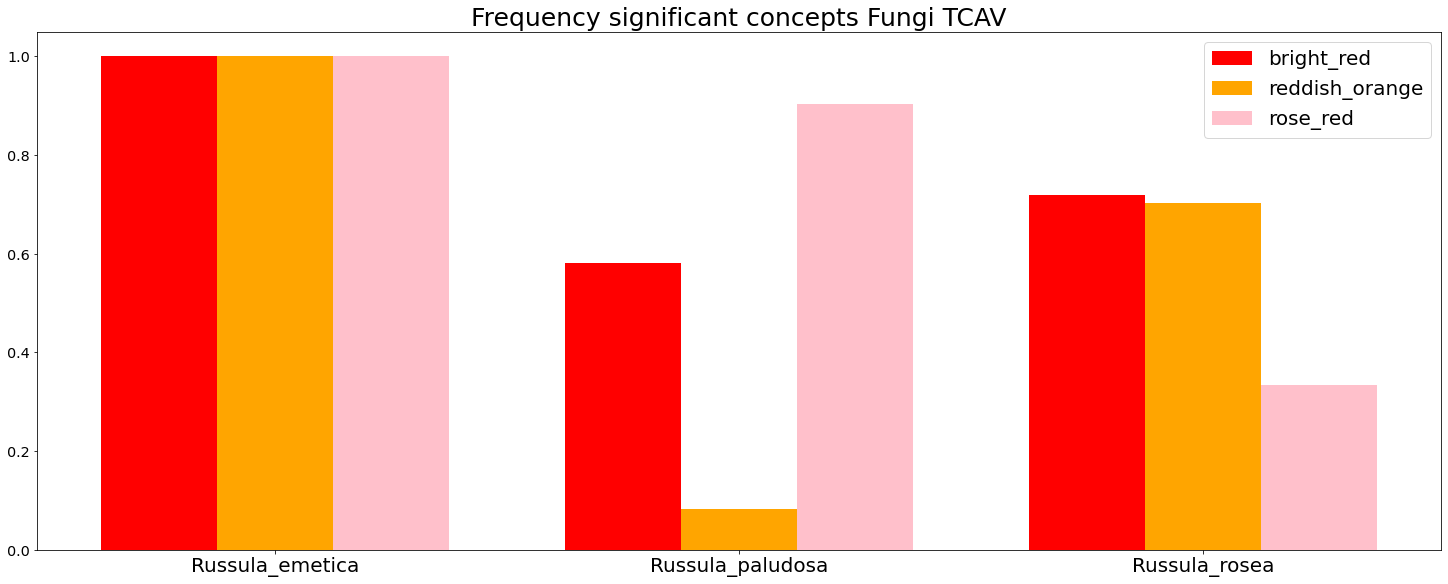

In [51]:
x = np.arange(len(classes))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0
con_colors = ['red', 'orange', 'pink']

plt.figure(figsize=(10,10))
fig, ax = plt.subplots(layout='constrained')
for i, (con, freq) in enumerate(pvals_con_dict.items()):
    offset = width * multiplier
    rects = ax.bar(x + offset, freq, width, label=con, color=con_colors[i])
    multiplier += 1

ax.set_title('Frequency significant concepts Fungi TCAV', fontsize=25)
ax.set_xticks(x + width, classes, fontsize=20)
ax.yaxis.set_tick_params(labelsize='x-large')
ax.legend(loc='upper right', fontsize=20)
plt.show()

### Plot Images along with Predicted Species, Confidence and TCAV Concepts (for XAI Group in Toloka)

In [29]:
BASE_PATH_CONCEPTS = './beexplainable/toloka/fungi/images/concepts/'
concept_paths = [BASE_PATH_CONCEPTS + 'xai_concepts_emetica_text.PNG',
                 BASE_PATH_CONCEPTS + 'xai_concepts_paludosa_text.PNG',
                 BASE_PATH_CONCEPTS + 'xai_concepts_rosea_text.PNG',
                 BASE_PATH_CONCEPTS + 'xai_concepts_none_text.png']
loaded_soft = np.load(metafolder + 'softmax_preds.npy')

In [ ]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
for img in task13_paths:
    img_id = img.split('/')[-1].split('_')[0] # i.e. the number in 2237915051-225385_rosea_hard_wrong.JPG
    for key in img_dict:
        if img_id in img_dict[key]:
            spec_pred_id = np.argmax(loaded_soft[int(key)-1], axis=-1)
            spec_pred_prob = int(np.round(np.max(loaded_soft[int(key)-1]),2)*100)

            ### Compute TCAV scores ###
            spec_to_load = classes.index(img_dict[key].split('/')[0]) # 0 indexed
            imgs_cav = [] # list of images for which to generate tcav-explanations
            file_cav = FUNGI_PATH + img_dict[key]
            img_cav = cv2.imread(file_cav)[...,::-1] / 255.0
            img_cav = tf.image.resize(img_cav, [img_width, img_height])
            imgs_cav.append(np.array(img_cav))
            imgs_cav = np.array(imgs_cav)

            tcav_scores = {}
            cls_name = classes[spec_to_load]
            tcav_scores[cls_name] = {}
            cav_tester = Tcav(model, layer_target)

            # For the chosen concept, we take all the CAVs and test them against that class
            for concept_name, _cavs in cavs.items():
                tcav_scores[cls_name][concept_name] = []
                for cav in _cavs:
                    score = cav_tester(imgs_cav, spec_to_load, cav)
                    tcav_scores[cls_name][concept_name].append(score)

            concept_score = []
            for concept_id, concept_name in enumerate(tcav_scores[cls_name].keys()):
                scores = tcav_scores[cls_name][concept_name]
                mean = np.mean(scores)
                std = np.std(scores)
                concept_score.append((concept_name, mean, std))

            means = [mean for concept_name, mean, std in concept_score]
            # The p-values will attest to the significance of a cav in relation to random cavs
            p_values = [ttest_ind(tcav_scores[cls_name][concept_name],
                                  tcav_scores[cls_name]['random'], equal_var = True)[1]
                        for concept_name in tcav_scores[cls_name].keys()]

            # Only consider highest mean concept stat. significant
            means_sig = np.asarray(means)[np.where(np.asarray(p_values[:-1]) < 0.05)]
            patch_id = np.argmax(means_sig) if len(means_sig) > 0 else 3

            ### Plots task for Toloka ###
            f, (a0, a1) = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [5, 3]})
            raw_file = '../data/DanishFungi/DF20M_3spec/' + img_dict[key]
            im = np.asarray( Image.open(raw_file).resize((448, 448)) )
            a0.imshow(im)
            a0.axes.get_xaxis().set_ticks([])
            a0.axes.get_yaxis().set_ticks([])

            con = np.asarray( Image.open(concept_paths[patch_id]).resize((620, 224)) )
            a1.imshow(con)
            a1.set_title('Our model is ' + str(spec_pred_prob) + '% confident\nthat this bee is ' + classes[spec_pred_id].replace('_', ' ') + ' because:',
                         color='red', fontsize=25, weight='bold')
            a1.axes.get_xaxis().set_ticks([])
            a1.axes.get_yaxis().set_ticks([])

            f.tight_layout()
            f.savefig('./beexplainable/toloka/fungi/images/task2_concepts_tcav_imgs/' + img.split('/')[-1])
            break